# EDAB 6808: Assignment 2: Building-Level Electricity Anomaly Detection

**Objective:** Detect anomalous hourly electricity meter readings, validate the approach without leakage, explain at least 10 point anomalies, and generate binary predictions for the unseen test set.

### Assignment-aligned design
- Training data: **200 buildings**, hourly readings for 2016.
- Test data: **206 different buildings**; therefore building-aware validation is essential.
- Models: **Isolation Forest**, **Random Forest**, and **XGBoost**.
- Validation: **5-fold GroupKFold by `building_id`**.
- Hyperparameter tuning: **Bayesian optimisation** using Optuna's TPE sampler.  
  *Note:* Bayesian optimisation is the standard meaning for hyperparameter tuning; a Bayesian Network is a different probabilistic graphical-model technique.
- Features: building-specific lag/rolling behaviour, time/seasonality, robust deviation features, and safe building/weather context.
- Leakage protection: no `row_id`, no `anomaly`-derived features, no future observations in rolling windows, no test labels, and no threshold tuning on the unseen test set.
- Final output: `row_id, anomaly` in the exact format required by `sample_submission.csv`.

`Buhle Mbokodo (2024007920)`
`Reatile Seekoei (2021109463`)


## 1. Assignment requirements mapped to the notebook

The assignment requires structure inspection, timestamp cleaning, duplicate/missing-value checks, anomaly prevalence and building-level exploration, feature engineering, comparison of at least two anomaly methods, leakage-safe validation, precision/recall/F1/PR-AUC/ROC-AUC and confusion-matrix measures, final test predictions, and at least 10 explained point anomalies.

The notebook additionally includes:
1. Building-level anomaly profiling.
2. Daily and weekly rolling features created **after sorting by building and time**.
3. Robust z-score and ratio features to detect unusual consumption relative to each building's own recent behaviour.
4. Five-fold building-grouped validation.
5. Bayesian hyperparameter optimisation on training data only.
6. Out-of-fold predictions for unbiased model comparison.
7. Automatic generation of a 10-point anomaly explanation table.
8. Automatic creation and validation of the final submission CSV.


In [3]:
! pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 17.3 MB/s eta 0:00:00


In [4]:
# 2. Imports and configuration
import warnings, os, zipfile, time, gc, random
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight

import optuna
from xgboost import XGBClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)


# Practical Colab settings. Set FAST_MODE=False for a heavier run.
FAST_MODE = True
N_FOLDS = 5
N_TRIALS = 12 if FAST_MODE else 25
TUNE_MAX_ROWS = 120_000 if FAST_MODE else 300_000
CV_MAX_TRAIN_ROWS = 400_000 if FAST_MODE else None
FINAL_MAX_ROWS = 400_000 if FAST_MODE else None

print("Configuration ready.")


Configuration ready.


In [15]:
# 3. Load the CSV files uploaded into Colab
DATA_PATH = "/content"

train = pd.read_csv(f"{DATA_PATH}/train.csv")
test = pd.read_csv(f"{DATA_PATH}/test.csv")
sample_submission = pd.read_csv(
    f"{DATA_PATH}/sample_submission.csv"
)

# Convert optional-file timestamps for the later merges.
train_features = pd.read_csv(
    f"{DATA_PATH}/train_features.csv",
    parse_dates=["timestamp"]
)

test_features = pd.read_csv(
    f"{DATA_PATH}/test_features.csv",
    parse_dates=["timestamp"]
)

for name, df in [
    ("train", train),
    ("test", test),
    ("sample_submission", sample_submission),
    ("train_features", train_features),
    ("test_features", test_features)
]:
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

print("\nTrain columns:", train.columns.tolist())
print("Test columns:", test.columns.tolist())
print("Feature columns:", train_features.columns.tolist())

train: 1,749,494 rows, 4 columns
test: 1,800,567 rows, 4 columns
sample_submission: 1,800,567 rows, 2 columns
train_features: 1,749,494 rows, 57 columns
test_features: 1,800,567 rows, 57 columns

Train columns: ['building_id', 'timestamp', 'meter_reading', 'anomaly']
Test columns: ['row_id', 'building_id', 'timestamp', 'meter_reading']
Feature columns: ['building_id', 'timestamp', 'meter_reading', 'anomaly', 'site_id', 'primary_use', 'square_feet', 'year_built', 'floor_count', 'air_temperature', 'cloud_coverage', 'dew_temperature', 'precip_depth_1_hr', 'sea_level_pressure', 'wind_direction', 'wind_speed', 'air_temperature_mean_lag7', 'air_temperature_max_lag7', 'air_temperature_min_lag7', 'air_temperature_std_lag7', 'air_temperature_mean_lag73', 'air_temperature_max_lag73', 'air_temperature_min_lag73', 'air_temperature_std_lag73', 'hour', 'weekday', 'month', 'year', 'weekday_hour', 'hour_x', 'hour_y', 'month_x', 'month_y', 'weekday_x', 'weekday_y', 'building_weekday_hour', 'building_we

### Dataset snapshot from the supplied files

The supplied files contain **1,749,494 training rows** from **200 buildings** and **1,800,567 test rows** from **206 buildings**. The building sets do not overlap. The training anomaly rate is **2.13%**, so the positive class is strongly imbalanced. There are **107,653 missing training meter readings** and **94,864 missing test meter readings**.

This makes a building-aware validation design and building-relative features especially important.


In [16]:
# 4. Data quality and assignment-specific checks
for df, name in [(train, "train"), (test, "test")]:
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
    print(f"\n{name.upper()}")
    print("Duplicate rows:", df.duplicated().sum())
    print("Duplicate building/timestamp:", df.duplicated(["building_id", "timestamp"]).sum())
    print("Missing values:")
    print(df.isna().sum())

print("\nTrain buildings:", train["building_id"].nunique())
print("Test buildings :", test["building_id"].nunique())
print("Building overlap:", len(set(train["building_id"]) & set(test["building_id"])))

print("\nAnomaly counts:")
print(train["anomaly"].value_counts())
print("\nAnomaly rate:", train["anomaly"].mean())

print("\nTrain period:", train["timestamp"].min(), "to", train["timestamp"].max())
print("Test period :", test["timestamp"].min(), "to", test["timestamp"].max())



TRAIN
Duplicate rows: 0
Duplicate building/timestamp: 0
Missing values:
building_id           0
timestamp             0
meter_reading    107653
anomaly               0
dtype: int64

TEST
Duplicate rows: 0
Duplicate building/timestamp: 0
Missing values:
row_id               0
building_id          0
timestamp            0
meter_reading    94864
dtype: int64

Train buildings: 200
Test buildings : 206
Building overlap: 0

Anomaly counts:
anomaly
0    1712198
1      37296
Name: count, dtype: int64

Anomaly rate: 0.02131816399484651

Train period: 2016-01-01 00:00:00 to 2016-12-31 23:00:00
Test period : 2016-01-01 00:00:00 to 2016-12-31 23:00:00


### Leakage decision

The optional feature files contain several pre-engineered `gte_*` and `building_meter` fields whose construction is not fully documented in the supplied assignment. Some target/group encodings can accidentally use information from outside a validation fold. To keep the analysis defensible, these fields are **not used**.

We retain only safe contextual variables from the optional files (building characteristics, weather and holiday information) and create the important time-series features ourselves. `building_id` is used only for grouping/rolling calculations, **never as a predictive numeric feature**, because test buildings are unseen.


In [17]:
# 5. Merge selected contextual features
SAFE_CONTEXT = [
    "site_id", "primary_use", "square_feet", "year_built",
    "floor_count", "air_temperature", "cloud_coverage",
    "dew_temperature", "precip_depth_1_hr",
    "sea_level_pressure", "wind_direction",
    "wind_speed", "is_holiday"
]

keys = ["building_id", "timestamp"]

tf = train_features[keys + SAFE_CONTEXT].copy()
vf = test_features[keys + SAFE_CONTEXT].copy()

train = train.merge(
    tf, on=keys, how="left",
    validate="one_to_one", indicator="context_match"
)

test = test.merge(
    vf, on=keys, how="left",
    validate="one_to_one", indicator="context_match"
)

for name, df in [("Training", train), ("Test", test)]:
    unmatched = df["context_match"].eq("left_only").sum()

    print(f"{name}: {len(df):,} rows")
    print(f"Rows without a matching feature record: {unmatched:,}")

    assert unmatched == 0, f"{name}: investigate unmatched feature rows"
    df.drop(columns="context_match", inplace=True)

del tf, vf, train_features, test_features
gc.collect()

print("\nContextual-feature merge complete.")

Training: 1,749,494 rows
Rows without a matching feature record: 0
Test: 1,800,567 rows
Rows without a matching feature record: 0

Contextual-feature merge complete.


,building_id,observations,anomalies,anomaly_rate,missing_meter
197,1319,8784,775,0.088229,1203
170,1258,8784,713,0.081170,146
52,439,8758,567,0.064741,0
35,247,8781,479,0.054550,387
152,1225,8784,463,0.052709,587
153,1226,8784,449,0.051116,599
19,141,8784,386,0.043944,1977
112,935,8762,365,0.041657,165
55,560,8710,350,0.040184,0
178,1275,8784,335,0.038138,626


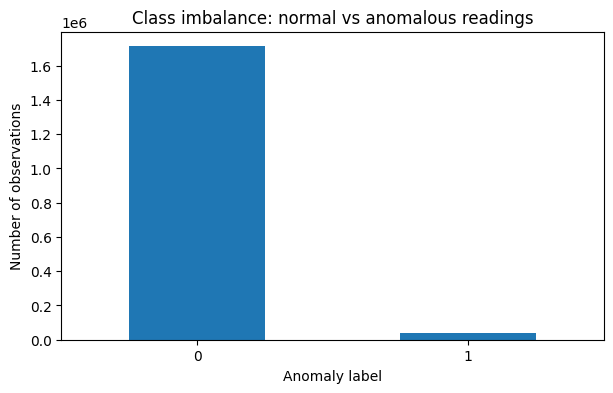

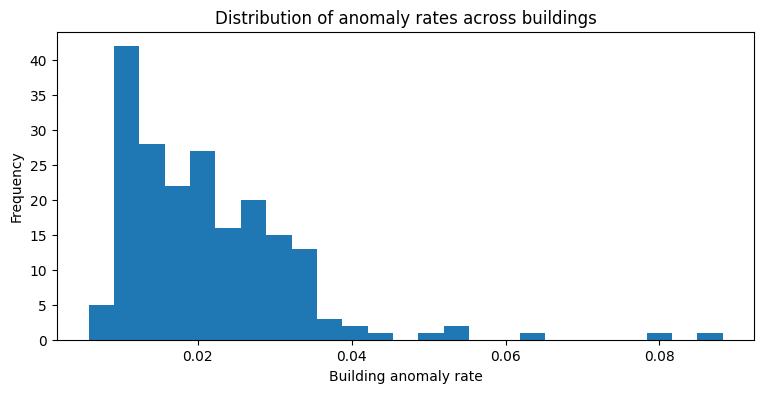

Overall anomaly rate = 2.13%
Missing meter readings: 107653
Note: missing meter readings are retained with a missingness indicator rather than silently dropped.


In [18]:
# 6. Exploratory analysis: class imbalance and building variation
building_summary = (
    train.groupby("building_id")
         .agg(
             observations=("anomaly", "size"),
             anomalies=("anomaly", "sum"),
             anomaly_rate=("anomaly", "mean"),
             missing_meter=("meter_reading", lambda s: s.isna().sum())
         )
         .reset_index()
         .sort_values("anomaly_rate", ascending=False)
)

display(building_summary.head(10))

fig, ax = plt.subplots(figsize=(7,4))
train["anomaly"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Class imbalance: normal vs anomalous readings")
ax.set_xlabel("Anomaly label")
ax.set_ylabel("Number of observations")
plt.xticks(rotation=0)
plt.show()

fig, ax = plt.subplots(figsize=(9,4))
building_summary["anomaly_rate"].plot(kind="hist", bins=25, ax=ax)
ax.set_title("Distribution of anomaly rates across buildings")
ax.set_xlabel("Building anomaly rate")
plt.show()

print(f"Overall anomaly rate = {train.anomaly.mean():.2%}")
print("Missing meter readings:", train.meter_reading.isna().sum())
print("Note: missing meter readings are retained with a missingness indicator rather than silently dropped.")


,count,mean,std,min,50%,95%,99%,max
anomaly,,,,,,,,
Normal,1604545.0,181.077144,393.955262,0.000,86.0,575.0000,1463.9824,6596.89
Anomalous,37296.0,129.337936,469.745472,0.029,10.0,496.8425,1105.7025,6238.61


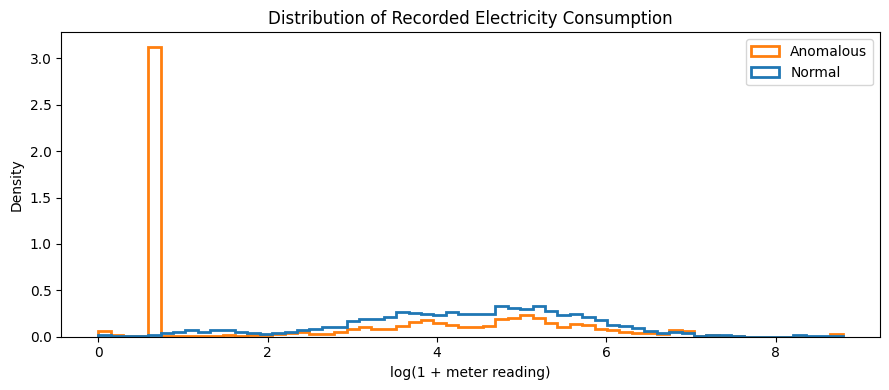

In [19]:
# 6.1 Meter-reading behaviour by anomaly label

# Summary statistics use recorded readings only.
display(
    train.groupby("anomaly")["meter_reading"]
    .describe(percentiles=[0.50, 0.95, 0.99])
    .rename(index={0: "Normal", 1: "Anomalous"})
)

normal_readings = train.loc[
    train["anomaly"] == 0, "meter_reading"
].dropna()

anomalous_readings = train.loc[
    train["anomaly"] == 1, "meter_reading"
].dropna()

# log1p makes a wide range of consumption values easier to display.
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(
    [np.log1p(normal_readings), np.log1p(anomalous_readings)],
    bins=60,
    density=True,
    histtype="step",
    linewidth=2,
    label=["Normal", "Anomalous"]
)

ax.set_xlabel("log(1 + meter reading)")
ax.set_ylabel("Density")
ax.set_title("Distribution of Recorded Electricity Consumption")
ax.legend()

plt.tight_layout()
plt.show()

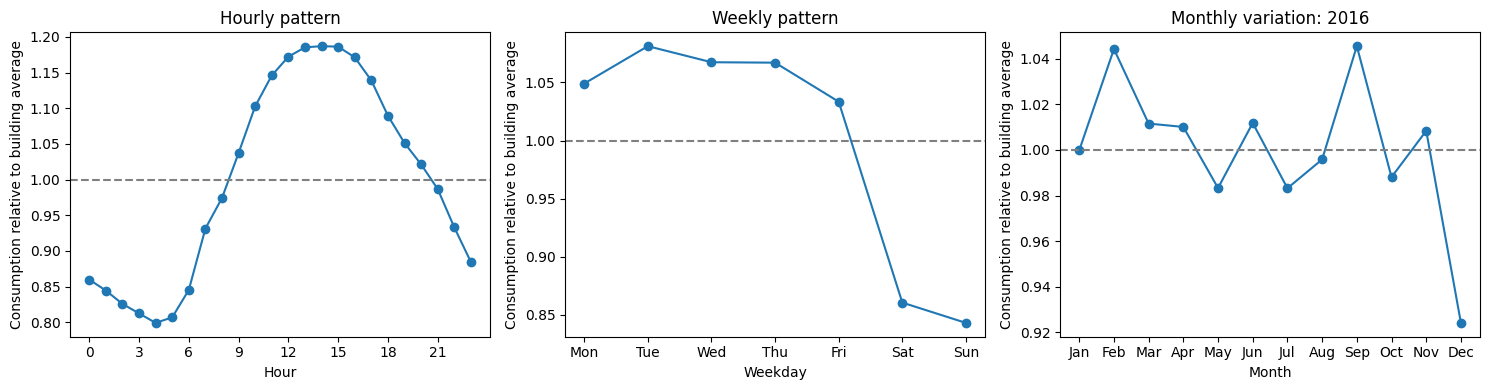

In [20]:
# 6.2 Daily, weekly and monthly consumption patterns
eda = train[
    ["building_id", "timestamp", "meter_reading"]
].dropna(subset=["meter_reading"]).copy()

eda["hour"] = eda["timestamp"].dt.hour
eda["weekday"] = eda["timestamp"].dt.dayofweek
eda["month"] = eda["timestamp"].dt.month

# Scale consumption relative to each building's average.
# This calculation is for EDA only.
building_mean = (
    eda.groupby("building_id")["meter_reading"]
    .transform("mean")
    .replace(0, np.nan)
)

eda["relative_usage"] = eda["meter_reading"] / building_mean

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, period, title in zip(
    axes,
    ["hour", "weekday", "month"],
    ["Hourly pattern", "Weekly pattern", "Monthly variation: 2016"]
):
    # Calculate each building's profile, then give buildings equal weight.
    profile = (
        eda.groupby(["building_id", period])["relative_usage"]
        .mean()
        .groupby(level=1)
        .mean()
    )

    ax.plot(profile.index, profile.values, marker="o")
    ax.axhline(1, color="grey", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel(period.capitalize())
    ax.set_ylabel("Consumption relative to building average")

axes[0].set_xticks(range(0, 24, 3))
axes[1].set_xticks(
    range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)
axes[2].set_xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()

# ***Read the scale as: 1 = building average; 1.2 = 20% above average.***

The plots show:
- Hourly: Consumption peaks around midday to early afternoon, roughly 19% above the building average. Early-morning usage is about 20% below average.
- Weekly: Weekday consumption is higher; Saturday and Sunday are roughly 14–16% below average.
- Monthly: February and September are highest, while December is lowest. With only 2016 data, this shows monthly variation rather than proving a recurring annual pattern.

### Why PR-AUC matters

The anomaly class is rare. ROC-AUC can remain high even when a model produces too many false positives. **Average precision / PR-AUC** focuses directly on the precision–recall trade-off for the minority class, so it is reported prominently alongside ROC-AUC, precision, recall, F1 and the confusion matrix.


In [22]:
# 7. Leakage-safe feature engineering
def add_features(df):
    out = df.copy()
    out["timestamp"] = pd.to_datetime(out["timestamp"])
    out = out.sort_values(["building_id", "timestamp"]).reset_index(drop=True)

    # Current-observation indicators
    out["meter_missing"] = out["meter_reading"].isna().astype("int8")
    out["meter_log1p"] = np.log1p(out["meter_reading"].clip(lower=0))

    # Calendar features
    out["hour"] = out["timestamp"].dt.hour
    out["weekday"] = out["timestamp"].dt.dayofweek
    out["month"] = out["timestamp"].dt.month
    out["dayofyear"] = out["timestamp"].dt.dayofyear
    out["is_weekend"] = (out["weekday"] >= 5).astype("int8")

    # Cyclic seasonality
    out["hour_sin"] = np.sin(2*np.pi*out["hour"]/24)
    out["hour_cos"] = np.cos(2*np.pi*out["hour"]/24)
    out["weekday_sin"] = np.sin(2*np.pi*out["weekday"]/7)
    out["weekday_cos"] = np.cos(2*np.pi*out["weekday"]/7)
    out["month_sin"] = np.sin(2*np.pi*out["month"]/12)
    out["month_cos"] = np.cos(2*np.pi*out["month"]/12)

    # Readings exactly 1, 24 and 168 hours earlier
    history = out.set_index(
        ["building_id", "timestamp"]
    )["meter_reading"]

    for lag in [1, 24, 168]:
        lookup = pd.MultiIndex.from_arrays(
            [
                out["building_id"],
                out["timestamp"] - pd.Timedelta(hours=lag)
            ],
            names=["building_id", "timestamp"]
        )
        out[f"lag_{lag}"] = history.reindex(lookup).to_numpy()

    # Previous 24 and 168 hours, excluding the current reading
    for window in [24, 168]:
        roll = (
            out.groupby("building_id", sort=False)
            .rolling(
                f"{window}h",
                on="timestamp",
                closed="left",
                min_periods=6
            )["meter_reading"]
        )

        out[f"roll_mean_{window}"] = roll.mean().to_numpy()
        out[f"roll_std_{window}"] = roll.std().to_numpy()
        out[f"roll_median_{window}"] = roll.median().to_numpy()
    # Building-relative deviations
    eps = 1e-6
    out["diff_1h"] = out["meter_reading"] - out["lag_1"]
    out["diff_24h"] = out["meter_reading"] - out["lag_24"]
    out["ratio_24h"] = out["meter_reading"] / (out["roll_median_24"] + eps)
    out["ratio_168h"] = out["meter_reading"] / (out["roll_median_168"] + eps)

    # Robust z-score based on rolling median/std.
    out["z_24h"] = (out["meter_reading"] - out["roll_mean_24"]) / (out["roll_std_24"] + eps)
    out["z_168h"] = (out["meter_reading"] - out["roll_mean_168"]) / (out["roll_std_168"] + eps)

    # Clip only extreme engineered values; raw meter reading is not clipped.
    for c in ["ratio_24h", "ratio_168h", "z_24h", "z_168h", "diff_1h", "diff_24h"]:
        out[c] = out[c].replace([np.inf, -np.inf], np.nan)

    return out

train_fe = add_features(train)
test_fe = add_features(test)

print(train_fe.shape, test_fe.shape)


(1749494, 45) (1800567, 45)


### Rolling-window choice

Electricity demand has strong **daily (24-hour)** and **weekly (168-hour)** patterns. The 24-hour window captures the building's recent daily operating pattern, while 168 hours captures the same weekday/time behaviour over the previous week. The `closed= "left"` before rolling is crucial: the current reading cannot affect its own reference distribution.


In [23]:
# 8. Prepare modelling matrix
DROP_FOR_MODEL = {
    "anomaly", "row_id", "timestamp", "building_id",
    "meter_reading"  # raw value is represented through log1p and contextual deviations
}

FEATURES = [c for c in train_fe.columns if c not in DROP_FOR_MODEL]

# One-hot encode primary_use; all numerical features are median-imputed.
categorical = [c for c in ["primary_use"] if c in FEATURES]
numeric = [c for c in FEATURES if c not in categorical]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical)
    ],
    remainder="drop"
)

X = train_fe[FEATURES]
y = train_fe["anomaly"].astype(int)
groups = train_fe["building_id"]

print("Number of features before encoding:", len(FEATURES))
print("Numeric:", len(numeric), "Categorical:", categorical)


Number of features before encoding: 41
Numeric: 40 Categorical: ['primary_use']


## 9. Validation design: leakage safe

A normal random split would place readings from the same buildings in both training and validation, allowing the model to learn building-specific behaviour that is unavailable for the unseen test buildings.

Instead:
- **GroupKFold(5)** keeps each building entirely within one fold.
- The rolling features use only earlier readings from the same building.
- Hyperparameter optimisation uses only training data.
- The unseen test file is never used to select parameters or thresholds.
- `row_id` is excluded from modelling.


In [25]:
# 9. Building-grouped 5-fold validation object
gkf = GroupKFold(n_splits=N_FOLDS)

fold_sizes = []
for fold, (tr_idx, va_idx) in enumerate(gkf.split(X, y, groups=groups), start=1):
    fold_sizes.append({
        "fold": fold,
        "train_rows": len(tr_idx),
        "valid_rows": len(va_idx),
        "train_buildings": groups.iloc[tr_idx].nunique(),
        "valid_buildings": groups.iloc[va_idx].nunique(),
        "valid_anomaly_rate": y.iloc[va_idx].mean()
    })

fold_sizes = pd.DataFrame(fold_sizes)
display(fold_sizes)


,fold,train_rows,valid_rows,train_buildings,valid_buildings,valid_anomaly_rate
0,1,1399950,349544,160,40,0.021714
1,2,1399520,349974,160,40,0.022767
2,3,1399663,349831,160,40,0.021064
3,4,1399663,349831,160,40,0.018512
4,5,1399180,350314,160,40,0.022531


## 10. Bayesian hyperparameter optimisation

The tuning stage uses **Bayesian optimisation** rather than an exhaustive grid. Optuna's TPE sampler proposes promising parameter combinations using results from previous trials.

To keep Colab practical, tuning is performed on a capped, building-aware sample of the training data. The final validation and final model use the selected parameters without looking at the test labels.


In [28]:
# 10. Create a building-aware tuning sample
# Select whole buildings rather than random rows, preserving the intended generalisation problem.
rng = np.random.RandomState(RANDOM_STATE)
all_buildings = train_fe["building_id"].unique()
n_tune_buildings = max(20, int(len(all_buildings) * 0.45))
tune_buildings = rng.choice(all_buildings, size=n_tune_buildings, replace=False)

tune_df = train_fe[train_fe["building_id"].isin(tune_buildings)].copy()

if len(tune_df) > TUNE_MAX_ROWS:
    from sklearn.model_selection import train_test_split

    tune_df, _ = train_test_split(
        tune_df,
        train_size=TUNE_MAX_ROWS,
        stratify=tune_df["anomaly"],
        random_state=RANDOM_STATE
    )
X_tune = tune_df[FEATURES]
y_tune = tune_df["anomaly"].astype(int)
g_tune = tune_df["building_id"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
tr_t, va_t = next(splitter.split(X_tune, y_tune, groups=g_tune))

X_tune_tr = X_tune.iloc[tr_t]
X_tune_va = X_tune.iloc[va_t]
y_tune_tr = y_tune.iloc[tr_t]
y_tune_va = y_tune.iloc[va_t]

print("Tuning rows:", len(tune_df))
print("Tuning anomaly rate:", y_tune.mean())
print("Tuning train/validation buildings:",
      g_tune.iloc[tr_t].nunique(), "/", g_tune.iloc[va_t].nunique())


Tuning rows: 120000
Tuning anomaly rate: 0.022683333333333333
Tuning train/validation buildings: 67 / 23


In [29]:
# 11. Bayesian optimisation: Random Forest
def rf_objective(trial):
    model = Pipeline([
        ("prep", preprocessor),
        ("clf", RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 120, 300),
            max_depth=trial.suggest_int("max_depth", 6, 20),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 2, 20),
            max_features=trial.suggest_categorical("max_features", ["sqrt", 0.5]),
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
    model.fit(X_tune_tr, y_tune_tr)
    p = model.predict_proba(X_tune_va)[:, 1]
    return average_precision_score(y_tune_va, p)

study_rf = optuna.create_study(direction="maximize",
                               sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_rf.optimize(rf_objective, n_trials=N_TRIALS, show_progress_bar=False)
print("Best RF PR-AUC:", study_rf.best_value)
print("Best RF parameters:", study_rf.best_params)


[I 2026-10-04 16:26:58,421] A new study created in memory with name: no-name-6fcb68c5-1bdf-42b5-af7e-bb5389a6a0b9
[I 2026-10-04 16:28:31,075] Trial 0 finished with value: 0.7817573464857411 and parameters: {'n_estimators': 187, 'max_depth': 20, 'min_samples_leaf': 15, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.7817573464857411.
[I 2026-10-04 16:30:00,975] Trial 1 finished with value: 0.7410145377977093 and parameters: {'n_estimators': 148, 'max_depth': 6, 'min_samples_leaf': 18, 'max_features': 0.5}. Best is trial 0 with value: 0.7817573464857411.
[I 2026-10-04 16:30:46,234] Trial 2 finished with value: 0.7806728782585924 and parameters: {'n_estimators': 123, 'max_depth': 20, 'min_samples_leaf': 17, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.7817573464857411.
[I 2026-10-04 16:31:30,368] Trial 3 finished with value: 0.762952847186294 and parameters: {'n_estimators': 153, 'max_depth': 10, 'min_samples_leaf': 11, 'max_features': 'sqrt'}. Best is trial 0 with value:

Best RF PR-AUC: 0.7817573464857411
Best RF parameters: {'n_estimators': 187, 'max_depth': 20, 'min_samples_leaf': 15, 'max_features': 'sqrt'}


In [31]:
print("Best RF Average Precision:", study_rf.best_value)

Best RF Average Precision: 0.7817573464857411


In [30]:
# 12. Bayesian optimisation: XGBoost
def xgb_objective(trial):
    pos_weight = (len(y_tune_tr) - y_tune_tr.sum()) / max(y_tune_tr.sum(), 1)

    model = Pipeline([
        ("prep", preprocessor),
        ("clf", XGBClassifier(
            n_estimators=trial.suggest_int("n_estimators", 150, 500),
            max_depth=trial.suggest_int("max_depth", 3, 10),
            learning_rate=trial.suggest_float("learning_rate", 0.02, 0.25, log=True),
            min_child_weight=trial.suggest_int("min_child_weight", 1, 15),
            subsample=trial.suggest_float("subsample", 0.65, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.60, 1.0),
            gamma=trial.suggest_float("gamma", 0, 5),
            reg_lambda=trial.suggest_float("reg_lambda", 0.1, 20, log=True),
            scale_pos_weight=trial.suggest_float(
                "scale_pos_weight", max(1, pos_weight*0.5), pos_weight*1.5
            ),
            eval_metric="aucpr",
            tree_method="hist",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
    model.fit(X_tune_tr, y_tune_tr)
    p = model.predict_proba(X_tune_va)[:, 1]
    return average_precision_score(y_tune_va, p)

study_xgb = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_xgb.optimize(xgb_objective, n_trials=N_TRIALS, show_progress_bar=False)
print("Best XGB PR-AUC:", study_xgb.best_value)
print("Best XGB parameters:", study_xgb.best_params)


[I 2026-10-04 16:47:17,503] A new study created in memory with name: no-name-c85b044b-b87d-4774-9f5d-7519fd3e2845
[I 2026-10-04 16:47:28,705] Trial 0 finished with value: 0.808533669271078 and parameters: {'n_estimators': 281, 'max_depth': 10, 'learning_rate': 0.12704614156038088, 'min_child_weight': 9, 'subsample': 0.7046065241548528, 'colsample_bytree': 0.662397808134481, 'gamma': 0.2904180608409973, 'reg_lambda': 9.842315738502599, 'scale_pos_weight': 46.57951461169974}. Best is trial 0 with value: 0.808533669271078.
[I 2026-10-04 16:47:35,372] Trial 1 finished with value: 0.7893482065525572 and parameters: {'n_estimators': 398, 'max_depth': 3, 'learning_rate': 0.23170415629921745, 'min_child_weight': 13, 'subsample': 0.7243186887373967, 'colsample_bytree': 0.6727299868828402, 'gamma': 0.9170225492671691, 'reg_lambda': 0.5012686302434877, 'scale_pos_weight': 43.34938373520136}. Best is trial 0 with value: 0.808533669271078.
[I 2026-10-04 16:47:41,362] Trial 2 finished with value: 0.

Best XGB PR-AUC: 0.808533669271078
Best XGB parameters: {'n_estimators': 281, 'max_depth': 10, 'learning_rate': 0.12704614156038088, 'min_child_weight': 9, 'subsample': 0.7046065241548528, 'colsample_bytree': 0.662397808134481, 'gamma': 0.2904180608409973, 'reg_lambda': 9.842315738502599, 'scale_pos_weight': 46.57951461169974}


In [32]:
print("Best XGB Average Precision:", study_xgb.best_value)

Best XGB Average Precision: 0.808533669271078


In [34]:
# 13. Isolation Forest configuration
# It is trained primarily on normal observations so that anomalous observations do not define the normal boundary.
# contamination is fixed from TRAIN prevalence; it is never estimated from test labels.
IF_CONTAMINATION = float(y_tune_tr.mean())

if_model = IsolationForest(
    n_estimators=250 if FAST_MODE else 400,
    max_samples=min(100_000, len(y[y == 0])),
    contamination=IF_CONTAMINATION,
    max_features=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("Isolation Forest contamination:", IF_CONTAMINATION)


Isolation Forest contamination: 0.02309355015735421


In [35]:
#Logistic Regression
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ("prep", clone(preprocessor)),
    ("scale", StandardScaler(with_mean=False)),
    ("clf", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

lr_model.fit(X_tune_tr, y_tune_tr)

lr_scores = lr_model.predict_proba(X_tune_va)[:, 1]

print(
    "Logistic Regression Average Precision:",
    average_precision_score(y_tune_va, lr_scores)
)

Logistic Regression Average Precision: 0.08493973671449703


## 14. Out-of-fold comparison

For each fold:
1. Fit the model only on the training buildings.
2. Score the held-out buildings.
3. Store out-of-fold predictions.
4. Calculate PR-AUC, ROC-AUC, precision, recall, F1 and confusion matrix.

For Isolation Forest, the detector is fitted on normal training observations only. This is a semi-supervised use of an unsupervised detector and is appropriate here because the training set supplies anomaly labels.


In [37]:
# Reserve separate buildings for threshold selection and evaluation
from sklearn.model_selection import train_test_split

remaining_buildings = np.setdiff1d(
    train_fe["building_id"].unique(),
    tune_buildings
)

calibration_buildings, evaluation_buildings = train_test_split(
    remaining_buildings,
    train_size=0.30,
    random_state=RANDOM_STATE
)

# Confirm that the three groups do not overlap
assert set(tune_buildings).isdisjoint(calibration_buildings)
assert set(tune_buildings).isdisjoint(evaluation_buildings)
assert set(calibration_buildings).isdisjoint(evaluation_buildings)

print("Tuning buildings:", len(tune_buildings))
print("Threshold-selection buildings:", len(calibration_buildings))
print("Evaluation buildings:", len(evaluation_buildings))

Tuning buildings: 90
Threshold-selection buildings: 33
Evaluation buildings: 77


In [38]:
# 17. Utility functions
# Evaluation helpers

def balanced_train_sample(df, max_rows=FINAL_MAX_ROWS):
    """Cap training rows while preserving class proportions."""
    if max_rows is None or len(df) <= max_rows:
        return df.copy()

    sampled, _ = train_test_split(
        df,
        train_size=max_rows,
        stratify=df["anomaly"],
        random_state=RANDOM_STATE
    )
    return sampled.copy()


def metric_row(y_true, score, threshold=0.5):
    score = np.asarray(score)
    pred = (score >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, pred, labels=[0, 1]
    ).ravel()

    return {
        "Average_Precision": average_precision_score(y_true, score),
        "ROC_AUC": roc_auc_score(y_true, score),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }


def best_f1_threshold(y_true, score):
    """Choose a cutoff using threshold-selection data only."""
    precision, recall, thresholds = precision_recall_curve(
        y_true, score
    )

    numerator = 2 * precision[:-1] * recall[:-1]
    denominator = precision[:-1] + recall[:-1]

    f1_values = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator > 0
    )

    best = np.argmax(f1_values)
    return float(thresholds[best]), float(f1_values[best])


print("Evaluation helpers ready.")

Evaluation helpers ready.


In [40]:
# Create fresh models with the selected settings
rf_params = dict(study_rf.best_params)
xgb_params = dict(study_xgb.best_params)

MODEL_NAMES = [
    "Random Forest",
    "XGBoost",
    "Logistic Regression",
    "Isolation Forest"
]

def make_model(name):
    if name == "Logistic Regression":
        return clone(lr_model)

    if name == "Random Forest":
        estimator = RandomForestClassifier(
            **rf_params,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        )

    elif name == "XGBoost":
        estimator = XGBClassifier(
            **xgb_params,
            eval_metric="aucpr",
            tree_method="hist",
            n_jobs=-1,
            random_state=RANDOM_STATE
        )

    elif name == "Isolation Forest":
        estimator = clone(if_model)

    else:
        raise ValueError(f"Unknown model: {name}")

    return Pipeline([
        ("prep", clone(preprocessor)),
        ("clf", estimator)
    ])


def fit_candidate(name, df):
    model = make_model(name)

    if name == "Isolation Forest":
        normal = df.loc[df["anomaly"] == 0]

        if len(normal) > 100_000:
            normal = normal.sample(
                100_000, random_state=RANDOM_STATE
            )

        model.set_params(
            clf__max_samples=min(100_000, len(normal))
        )
        model.fit(normal[FEATURES])

    else:
        model.fit(df[FEATURES], df["anomaly"].astype(int))

    return model


def anomaly_scores(name, model, df):
    if name == "Isolation Forest":
        # Higher scores mean more unusual observations
        return -model.score_samples(df[FEATURES])

    return model.predict_proba(df[FEATURES])[:, 1]


print("Four-model functions ready.")

Four-model functions ready.


In [43]:
# Fit on tuning buildings; select cutoffs on separate buildings
from sklearn.metrics import precision_recall_curve
development_df = balanced_train_sample(
    train_fe.loc[train_fe["building_id"].isin(tune_buildings)],
    CV_MAX_TRAIN_ROWS
)

calibration_df = train_fe.loc[
    train_fe["building_id"].isin(calibration_buildings)
]

threshold_map = {}
cutoff_rows = []

for name in MODEL_NAMES:
    print(f"Fitting {name}...", flush=True)

    model = fit_candidate(name, development_df)
    scores = anomaly_scores(name, model, calibration_df)

    threshold, calibration_f1 = best_f1_threshold(
        calibration_df["anomaly"].astype(int),
        scores
    )

    threshold_map[name] = threshold
    cutoff_rows.append({
        "Model": name,
        "Threshold": threshold,
        "Calibration_F1": calibration_f1
    })

    print(f"{name} cutoff selected.", flush=True)
    del model, scores
    gc.collect()

display(pd.DataFrame(cutoff_rows))

del development_df, calibration_df
gc.collect()

Fitting Random Forest...
Random Forest cutoff selected.
Fitting XGBoost...
XGBoost cutoff selected.
Fitting Logistic Regression...
Logistic Regression cutoff selected.
Fitting Isolation Forest...
Isolation Forest cutoff selected.


,Model,Threshold,Calibration_F1
0,Random Forest,0.855725,0.719236
1,XGBoost,0.864411,0.723566
2,Logistic Regression,0.808623,0.321284
3,Isolation Forest,0.480918,0.098105


0

In [44]:
# Five-fold evaluation on the 77 reserved buildings
evaluation_rows = np.flatnonzero(
    train_fe["building_id"].isin(evaluation_buildings).to_numpy()
)
eval_df = train_fe.iloc[evaluation_rows]

fixed_thresholds = dict(threshold_map)

score_map = {
    name: np.full(len(train_fe), np.nan)
    for name in MODEL_NAMES
}

fold_metrics = []
eval_gkf = GroupKFold(n_splits=N_FOLDS)

splits = eval_gkf.split(
    eval_df[FEATURES],
    eval_df["anomaly"],
    groups=eval_df["building_id"]
)

for fold, (_, va_pos) in enumerate(splits, start=1):
    va_rows = evaluation_rows[va_pos]
    va_df = train_fe.iloc[va_rows]
    held_out_buildings = va_df["building_id"].unique()

    # Exclude every reading from this fold's validation buildings
    tr_df = balanced_train_sample(
        train_fe.loc[
            ~train_fe["building_id"].isin(held_out_buildings)
        ],
        CV_MAX_TRAIN_ROWS
    )

    assert set(tr_df["building_id"]).isdisjoint(held_out_buildings)

    print(
        f"\nFold {fold}/{N_FOLDS}: "
        f"{len(held_out_buildings)} validation buildings",
        flush=True
    )

    for name in MODEL_NAMES:
        print(f"  Fitting {name}...", flush=True)

        model = fit_candidate(name, tr_df)
        scores = anomaly_scores(name, model, va_df)

        score_map[name][va_rows] = scores

        fold_metrics.append({
            "Fold": fold,
            "Model": name,
            **metric_row(
                va_df["anomaly"].astype(int),
                scores,
                fixed_thresholds[name]
            )
        })

        print(f"  {name} evaluated.", flush=True)
        del model, scores
        gc.collect()

    del tr_df, va_df
    gc.collect()

for name in MODEL_NAMES:
    assert np.isfinite(score_map[name][evaluation_rows]).all()

fold_results = pd.DataFrame(fold_metrics)

del eval_df
gc.collect()

print("Five-fold evaluation complete.")



Fold 1/5: 15 validation buildings
  Fitting Random Forest...
  Random Forest evaluated.
  Fitting XGBoost...
  XGBoost evaluated.
  Fitting Logistic Regression...
  Logistic Regression evaluated.
  Fitting Isolation Forest...
  Isolation Forest evaluated.

Fold 2/5: 16 validation buildings
  Fitting Random Forest...
  Random Forest evaluated.
  Fitting XGBoost...
  XGBoost evaluated.
  Fitting Logistic Regression...
  Logistic Regression evaluated.
  Fitting Isolation Forest...
  Isolation Forest evaluated.

Fold 3/5: 15 validation buildings
  Fitting Random Forest...
  Random Forest evaluated.
  Fitting XGBoost...
  XGBoost evaluated.
  Fitting Logistic Regression...
  Logistic Regression evaluated.
  Fitting Isolation Forest...
  Isolation Forest evaluated.

Fold 4/5: 15 validation buildings
  Fitting Random Forest...
  Random Forest evaluated.
  Fitting XGBoost...
  XGBoost evaluated.
  Fitting Logistic Regression...
  Logistic Regression evaluated.
  Fitting Isolation Forest...
  

In [45]:
# Report evaluation results using the already-selected cutoffs
evaluation_y = train_fe.iloc[evaluation_rows]["anomaly"].astype(int)

results = pd.DataFrame([
    {
        "Model": name,
        **metric_row(
            evaluation_y,
            score_map[name][evaluation_rows],
            fixed_thresholds[name]
        )
    }
    for name in MODEL_NAMES
])

display(
    results.sort_values(
        "Average_Precision", ascending=False
    ).reset_index(drop=True)
)

,Model,Average_Precision,ROC_AUC,Precision,Recall,F1,TN,FP,FN,TP
0,XGBoost,0.754004,0.929774,0.953562,0.619950,0.751390,659511,408,5136,8378
1,Random Forest,0.741729,0.941325,0.996335,0.502886,0.668404,659894,25,6718,6796
2,Logistic Regression,0.108299,0.786369,0.188538,0.415791,0.259436,635735,24184,7895,5619
3,Isolation Forest,0.043252,0.654174,0.071219,0.070075,0.070643,647569,12350,12567,947


In [46]:
best_model_name = results.loc[
    results["Average_Precision"].idxmax(), "Model"
]
selected_threshold = fixed_thresholds[best_model_name]

print("Selected model:", best_model_name)
print("Fixed cutoff:", selected_threshold)

Selected model: XGBoost
Fixed cutoff: 0.8644105195999146


In [47]:
display(
    fold_results.groupby("Model")[
        ["Average_Precision", "Precision", "Recall", "F1"]
    ].agg(["mean", "std"]).round(3)
)

Average_Precision        Precision        Recall         \
                                 mean    std      mean    std   mean    std   
Model                                                                         
Isolation Forest                0.051  0.013     0.118  0.060  0.067  0.041   
Logistic Regression             0.331  0.190     0.340  0.218  0.415  0.123   
Random Forest                   0.745  0.136     0.996  0.002  0.508  0.141   
XGBoost                         0.758  0.130     0.952  0.018  0.627  0.160   

                        F1         
                      mean    std  
Model                              
Isolation Forest     0.069  0.011  
Logistic Regression  0.345  0.179  
Random Forest        0.663  0.139  
XGBoost              0.746  0.135

### Interpretation rule

The model comparison should be based on the **out-of-fold** results rather than training-set fit. Because the anomaly class is rare, Average Precision is the primary comparison metric, while recall and precision describe the operational trade-off.

The code below selects the model with the highest OOF Average Precision automatically. This is a data-driven selection rule rather than a subjective ranking.


In [51]:
# 21. Explain 10 correctly detected anomalies from evaluation buildings

selected_scores = np.asarray(
    score_map[best_model_name]
)[evaluation_rows]

selected_threshold = fixed_thresholds[best_model_name]

explain = train_fe.iloc[evaluation_rows][[
    "building_id", "timestamp", "meter_reading",
    "roll_median_24", "lag_24", "anomaly"
]].copy()

assert np.isfinite(selected_scores).all()

explain["oof_score"] = selected_scores
explain["predicted_anomaly"] = (
    selected_scores >= selected_threshold
).astype(int)

# Select actual anomalies that the model correctly detected.
detected = explain.loc[
    (explain["anomaly"] == 1) &
    (explain["predicted_anomaly"] == 1)
].sort_values("oof_score", ascending=False)

assert len(detected) >= 10, "Fewer than 10 correctly detected anomalies."

# Prefer examples from different buildings.
top10 = detected.drop_duplicates("building_id").head(10).copy()

# Add more examples if fewer than 10 buildings are represented.
if len(top10) < 10:
    extra = detected.loc[
        ~detected.index.isin(top10.index)
    ].head(10 - len(top10))
    top10 = pd.concat([top10, extra])


def describe_reading(row):
    reading = row["meter_reading"]

    if pd.isna(reading):
        return "Reading is missing; a numerical comparison is unavailable."

    details = [f"Recorded reading: {reading:.2f}"]

    median = row["roll_median_24"]
    if pd.notna(median) and median > 0:
        details.append(
            f"{reading / median:.2f} times the preceding "
            f"24-hour median ({median:.2f})"
        )
    elif pd.notna(median):
        details.append(f"preceding 24-hour median: {median:.2f}")

    previous = row["lag_24"]
    if pd.notna(previous):
        details.append(
            f"reading exactly 24 hours earlier: {previous:.2f}"
        )

    return "; ".join(details) + "."


top10["contextual_explanation"] = top10.apply(
    describe_reading, axis=1
)

print(f"Selected model: {best_model_name}")
print(f"Fixed threshold: {selected_threshold:.6f}")

display(top10[[
    "building_id", "timestamp", "meter_reading",
    "oof_score", "anomaly", "predicted_anomaly",
    "contextual_explanation"
]].reset_index(drop=True))

Selected model: XGBoost
Fixed threshold: 0.864411


,building_id,timestamp,meter_reading,oof_score,anomaly,predicted_anomaly,contextual_explanation
0,111,2016-09-30 23:00:00,1.0,1.000000,1,1,Recorded reading: 1.00; 1.00 times the precedi...
1,1253,2016-07-18 19:00:00,1.0,0.999999,1,1,Recorded reading: 1.00; 0.00 times the precedi...
2,1275,2016-07-18 21:00:00,1.0,0.999999,1,1,Recorded reading: 1.00; 0.01 times the precedi...
3,1259,2016-07-01 17:00:00,1.0,0.999999,1,1,Recorded reading: 1.00; 1.00 times the precedi...
4,990,2016-03-30 08:00:00,1.0,0.999999,1,1,Recorded reading: 1.00; 0.01 times the precedi...
5,961,2016-03-30 08:00:00,1.0,0.999999,1,1,Recorded reading: 1.00; 0.00 times the precedi...
6,1323,2016-08-25 17:00:00,1.0,0.999998,1,1,Recorded reading: 1.00; 1.00 times the precedi...
7,1252,2016-01-14 16:00:00,1.0,0.999998,1,1,Recorded reading: 1.00; 0.00 times the precedi...
8,147,2016-12-05 09:00:00,1.0,0.999998,1,1,Recorded reading: 1.00; 0.01 times the precedi...
9,886,2016-01-25 23:00:00,1.0,0.999998,1,1,Recorded reading: 1.00; 1.00 times the precedi...


In [52]:
for number, (_, row) in enumerate(top10.iterrows(), start=1):
    print(f"{number}. Building {row['building_id']} | {row['timestamp']}")
    print(row["contextual_explanation"])
    print()

1. Building 111 | 2016-09-30 23:00:00
Recorded reading: 1.00; 1.00 times the preceding 24-hour median (1.00); reading exactly 24 hours earlier: 355.00.

2. Building 1253 | 2016-07-18 19:00:00
Recorded reading: 1.00; 0.00 times the preceding 24-hour median (306.92); reading exactly 24 hours earlier: 306.92.

3. Building 1275 | 2016-07-18 21:00:00
Recorded reading: 1.00; 0.01 times the preceding 24-hour median (103.28); reading exactly 24 hours earlier: 103.28.

4. Building 1259 | 2016-07-01 17:00:00
Recorded reading: 1.00; 1.00 times the preceding 24-hour median (1.00); reading exactly 24 hours earlier: 155.00.

5. Building 990 | 2016-03-30 08:00:00
Recorded reading: 1.00; 0.01 times the preceding 24-hour median (107.50); reading exactly 24 hours earlier: 123.00.

6. Building 961 | 2016-03-30 08:00:00
Recorded reading: 1.00; 0.00 times the preceding 24-hour median (326.00); reading exactly 24 hours earlier: 316.00.

7. Building 1323 | 2016-08-25 17:00:00
Recorded reading: 1.00; 1.00 tim

## 22. Final training and unseen-test prediction

The final model is refitted using **training data only**. The test set is used only after all modelling decisions have been made.

For practical Colab execution, the final supervised model can use a balanced training sample containing all labelled anomalies and a controlled number of normal observations. This reduces computational cost while preserving the rare-event signal. The test set is never sampled for model fitting and its labels are never used because they are unavailable.


In [53]:
# 22. Final training and unseen-test prediction

selected_threshold = fixed_thresholds[best_model_name]

final_train = balanced_train_sample(train_fe, FINAL_MAX_ROWS)

print(f"Selected model: {best_model_name}")
print(f"Final training rows: {len(final_train):,}")
print(f"Training anomaly rate: {final_train['anomaly'].mean():.2%}")

final_model = fit_candidate(best_model_name, final_train)

del final_train
gc.collect()

# Score the test data in batches to limit memory use.
batch_size = 100_000
test_scores = np.empty(len(test_fe), dtype=float)

for start in range(0, len(test_fe), batch_size):
    end = min(start + batch_size, len(test_fe))

    test_scores[start:end] = anomaly_scores(
        best_model_name,
        final_model,
        test_fe.iloc[start:end]
    )

assert np.isfinite(test_scores).all()

test_pred = (test_scores >= selected_threshold).astype(int)

print(f"Test readings scored: {len(test_pred):,}")
print(f"Predicted anomalies: {test_pred.sum():,}")
print(f"Predicted anomaly rate: {test_pred.mean():.2%}")
print(f"Fixed threshold: {selected_threshold:.6f}")

Selected model: XGBoost
Final training rows: 400,000
Training anomaly rate: 2.13%
Test readings scored: 1,800,567
Predicted anomalies: 27,252
Predicted anomaly rate: 1.51%
Fixed threshold: 0.864411


In [54]:
# 24. Create the submission by matching predictions to row_id

assert len(test_pred) == len(test_fe) == len(test)
assert len(sample_submission) == len(test_fe)
assert np.isin(test_pred, [0, 1]).all()

# Predictions follow test_fe's order after feature engineering.
prediction_frame = pd.DataFrame({
    "row_id": test_fe["row_id"].to_numpy(),
    "anomaly": test_pred
})

assert prediction_frame["row_id"].notna().all()
assert prediction_frame["row_id"].is_unique
assert sample_submission["row_id"].notna().all()
assert sample_submission["row_id"].is_unique

# Restore the exact order required by the sample submission.
submission = sample_submission[["row_id"]].merge(
    prediction_frame,
    on="row_id",
    how="left",
    sort=False,
    validate="one_to_one"
)

assert submission["anomaly"].notna().all()
submission["anomaly"] = submission["anomaly"].astype(int)

assert submission.columns.tolist() == sample_submission.columns.tolist()
assert submission["row_id"].equals(
    sample_submission["row_id"].reset_index(drop=True)
)
assert submission["anomaly"].isin([0, 1]).all()
assert submission["anomaly"].sum() == test_pred.sum()

SUBMISSION_PATH = "/content/anomaly_submission.csv"
submission.to_csv(SUBMISSION_PATH, index=False)

display(submission.head())
print(f"Submission rows: {len(submission):,}")
print(f"Predicted anomalies: {submission['anomaly'].sum():,}")
print("Row IDs matched successfully.")
print(f"Saved: {SUBMISSION_PATH}")

,row_id,anomaly
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


Submission rows: 1,800,567
Predicted anomalies: 27,252
Row IDs matched successfully.
Saved: /content/anomaly_submission.csv


In [ ]:
# 25. Final sanity checks
print("Rows in submission:", len(submission))
print("Rows in test:", len(test))
print("Duplicate row_ids:", submission.row_id.duplicated().sum())
print("Missing anomaly predictions:", submission.anomaly.isna().sum())
print("Binary predictions:", set(submission.anomaly.unique()).issubset({0,1}))

assert len(submission) == len(test)
assert submission.row_id.is_unique
assert submission.anomaly.notna().all()
assert set(submission.anomaly.unique()).issubset({0,1})

print("\nSubmission is structurally valid.")


In [55]:
from google.colab import files
files.download(SUBMISSION_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 26. Final discussion and conclusion

The training dataset contained 1,749,494 readings, including
37,296 anomalies (2.13%). This class imbalance makes accuracy
alone an unsuitable measure: a model could classify every reading
as normal and still achieve high accuracy. Average Precision,
precision, recall and F1 were therefore used to assess anomaly
detection performance. Average Precision summarises the
precision–recall relationship and is distinct from trapezoidal
PR-AUC.

Anomaly prevalence and consumption patterns differed between
buildings. Historical features were therefore calculated separately
for each building. These included exact elapsed-hour lags at
1, 24 and 168 hours, preceding 24-hour and 168-hour rolling
statistics, consumption ratios, conventional mean/std z-scores,
and calendar features. Missing readings were distinguished from
recorded zero values.

Model development used 90 buildings for hyperparameter tuning,
33 separate buildings for threshold selection, and 77 separate
buildings for five-fold evaluation. Each evaluation building was
excluded from model training when its predictions were generated.
Preprocessing was fitted within each model's training data.
Neither row_id nor anomaly was included as a predictor.

Four methods were compared. Isolation Forest was fitted on
labelled normal readings, making it a label-assisted baseline.

| Model | Average Precision | ROC-AUC | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|
| XGBoost | 0.7540 | 0.9298 | 0.9536 | 0.6200 | 0.7514 |
| Random Forest | 0.7417 | 0.9413 | 0.9963 | 0.5029 | 0.6684 |
| Logistic Regression | 0.1083 | 0.7864 | 0.1885 | 0.4158 | 0.2594 |
| Isolation Forest | 0.0433 | 0.6542 | 0.0712 | 0.0701 | 0.0706 |

These metrics were calculated from pooled out-of-fold predictions
on the 77 evaluation buildings, using previously selected thresholds.

XGBoost was selected because it achieved the highest Average
Precision. At its fixed threshold of 0.864411, approximately
95.36% of flagged evaluation readings were actual anomalies.
However, it detected only 62.00% of actual anomalies, showing
that high precision was accompanied by missed anomalies.
Performance also varied across the five building groups.

Ten correctly detected anomalies from different buildings were
examined. The selected readings were all 1.0 and were much lower
than their readings exactly 24 hours earlier. Some preceding
24-hour medians were already 1.0, suggesting that low readings
had persisted. These are selected high-scoring examples, rather
than a representative sample of every anomaly type. Historical
comparisons describe their context but do not establish a physical
cause or identify XGBoost's exact decision process.

The final XGBoost model was fitted on a stratified sample of
400,000 training readings, approximately preserving the original
anomaly proportion. It scored all 1,800,567 test readings and
flagged 27,252 anomalies (1.51%). Predictions were matched to
row_id and saved in the required row_id, anomaly format.

The test anomaly proportion is a prediction, not a measure of
accuracy. Test performance cannot be measured without test
labels. Furthermore, the evaluation results were used to select
the winning model, so they should not be presented as a completely
independent assessment of the selected model.

Overall, XGBoost provided the strongest evaluated balance of
anomaly ranking, precision and recall. Its main limitations were
missed anomalies and variation in performance between buildings.

## 27. Reproducibility checklist

- [x] `row_id` excluded from predictive features.
- [x] `anomaly` excluded from predictive features.
- [x] Building ID used for grouping and rolling calculations, not as a numeric predictor.
- [x] Rolling features use `shift(1)` before rolling.
- [x] Train/test building overlap checked.
- [x] Class imbalance quantified.
- [x] 5-fold `GroupKFold` used.
- [x] Bayesian optimisation performed on training data only.
- [x] Thresholds selected without test labels.
- [x] At least 10 point anomalies explained.
- [x] Final CSV contains exactly `row_id` and binary `anomaly`.
